## Load and split the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

df = pd.read_csv(Path("heart attack analysis.csv"))
X = df.drop(columns="output")
y = df["output"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Rows/columns:", df.shape, "Missing:", int(df.isna().sum().sum()))

Rows/columns: (303, 14) Missing: 0


In [2]:
criterion_results = []
for criterion, label in [("entropy", "Entropy (ID3-style)"), ("gini", "Gini (CART)")]:
    model = DecisionTreeClassifier(criterion=criterion, max_depth=4, random_state=42)
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    criterion_results.append((label, train_acc, test_acc))
    print(f"{label}: train accuracy={train_acc:.3f}, holdout accuracy={test_acc:.3f}")

Entropy (ID3-style): train accuracy=0.890, holdout accuracy=0.776
Gini (CART): train accuracy=0.916, holdout accuracy=0.737


## Effect of tree parameters

The sweep changes `criterion`, `min_samples_split`, `min_samples_leaf`, and `max_depth`. The difference between training and holdout accuracy can indicate overfitting.

,criterion,max_depth,min_samples_split,min_samples_leaf,train_accuracy,test_accuracy
0,gini,1,2,1,0.779736,0.697368
1,gini,1,10,3,0.779736,0.697368
2,gini,2,2,1,0.801762,0.671053
3,gini,2,10,3,0.801762,0.671053
4,gini,3,2,1,0.859031,0.736842
5,gini,3,10,3,0.859031,0.736842
6,gini,4,2,1,0.916300,0.736842
7,gini,4,10,3,0.894273,0.697368
8,gini,6,2,1,0.964758,0.710526
9,gini,6,10,3,0.907489,0.631579


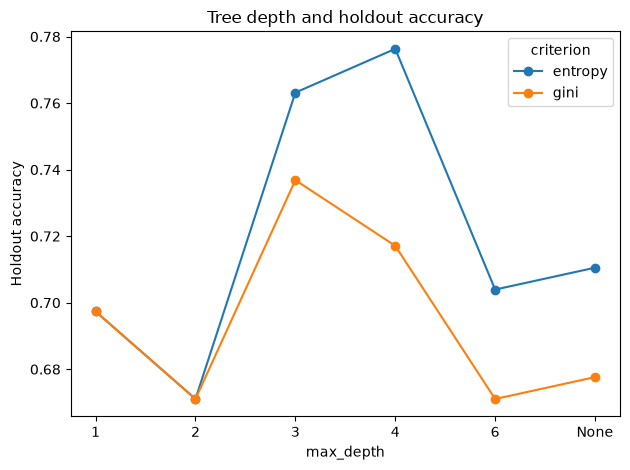

In [3]:
rows = []
for criterion in ("gini", "entropy"):
    for max_depth in (1, 2, 3, 4, 6, None):
        for min_split, min_leaf in ((2, 1), (10, 3)):
            model = DecisionTreeClassifier(
                criterion=criterion, max_depth=max_depth,
                min_samples_split=min_split, min_samples_leaf=min_leaf,
                random_state=42
            )
            model.fit(X_train, y_train)
            rows.append({
                "criterion": criterion, "max_depth": str(max_depth),
                "min_samples_split": min_split, "min_samples_leaf": min_leaf,
                "train_accuracy": model.score(X_train, y_train),
                "test_accuracy": model.score(X_test, y_test),
            })
results = pd.DataFrame(rows)
display(results)
results.to_csv("tree_parameter_results.csv", index=False)
results.pivot_table(index="max_depth", columns="criterion", values="test_accuracy").plot(marker="o")
plt.ylabel("Holdout accuracy"); plt.title("Tree depth and holdout accuracy")
plt.tight_layout(); plt.show()

## Visualize an entropy tree

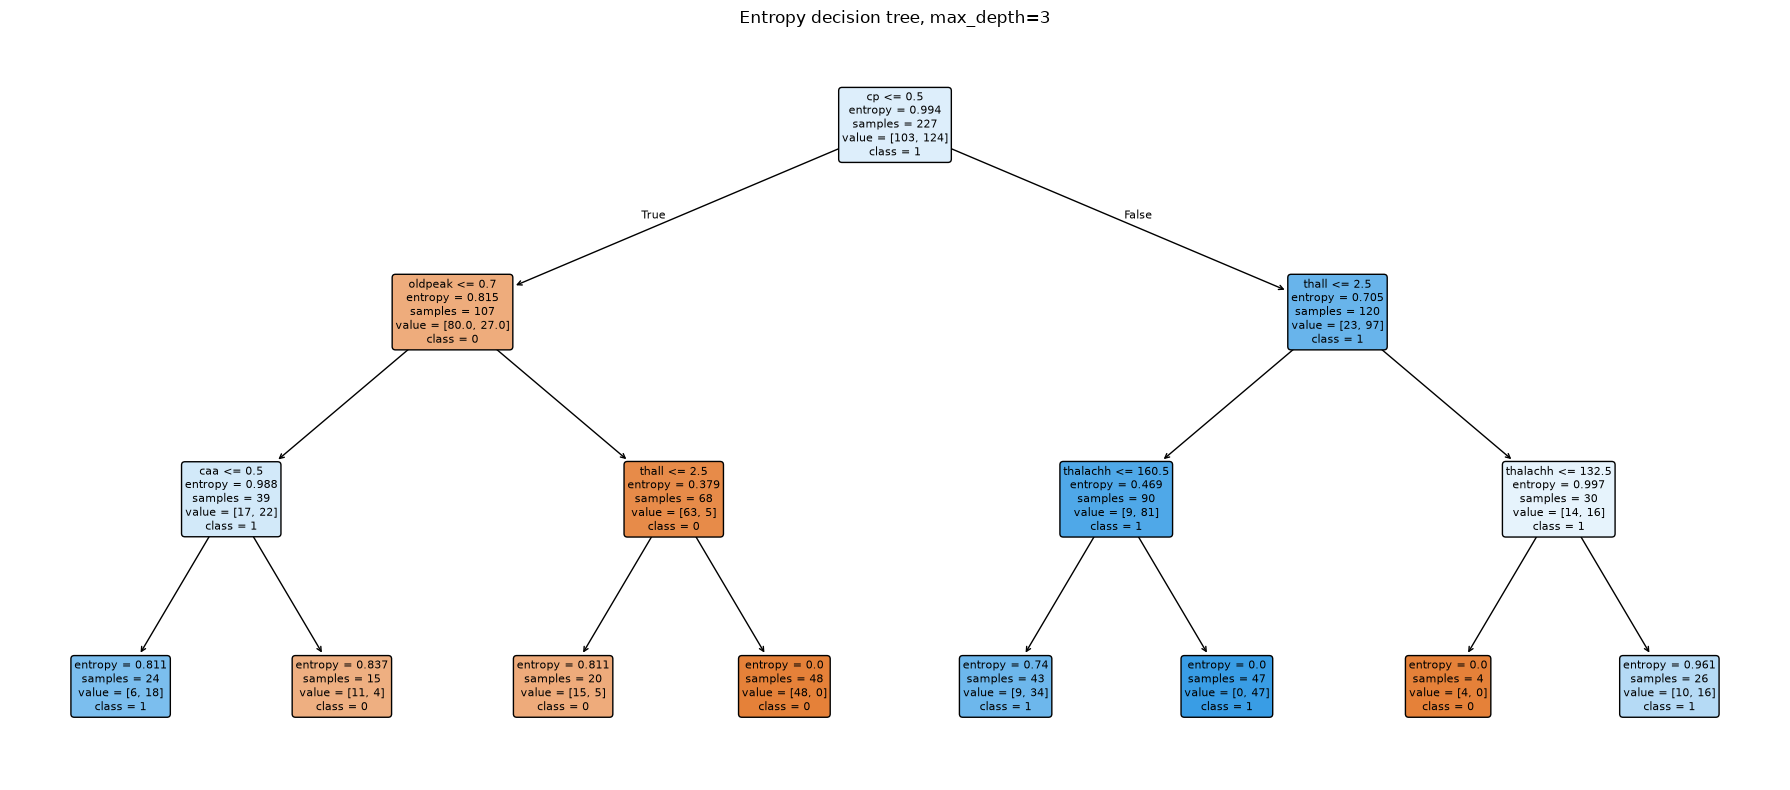

In [4]:
final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
final_tree.fit(X_train, y_train)
plt.figure(figsize=(18, 8))
plot_tree(final_tree, feature_names=X.columns, class_names=["0", "1"],
          filled=True, rounded=True, fontsize=8)
plt.title("Entropy decision tree, max_depth=3")
plt.tight_layout(); plt.show()